# Pronóstico de cierre 2026 de delitos de alto impacto social

Este notebook documenta el análisis que alimenta el dashboard (`app.py`). Los datos son registros oficiales de la Policía Nacional (2020 a julio de 2026) de seis delitos: violencia intrafamiliar, amenazas, delitos sexuales, homicidio, extorsión y secuestro.

**Pregunta:** con los casos observados hasta julio, ¿cuántos casos tendrá cada departamento y tipo de delito al cierre de 2026?

$$\text{cierre} = \text{casos observados ene-jul} + \text{pronóstico ago-dic}$$


## 1. Preparación

Los resultados ya están en `outputs/`. Para reproducirlos desde cero: `python -m src.ingesta`, `python -m src.agregar` y `python entrenar_modelo.py` (ver README).


In [1]:
import sys
from pathlib import Path
import json

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from entrenar_modelo import construir_panel
from src.config import CORTE_ANIO, CORTE_MES

data = pd.read_csv(RAIZ / 'data' / 'delitos_mensual.csv')
panel = construir_panel(data)
resultados = pd.read_csv(RAIZ / 'outputs' / 'comparacion_modelos.csv')
backtest = pd.read_csv(RAIZ / 'outputs' / 'backtest_cierres.csv')
cierre = pd.read_csv(RAIZ / 'outputs' / 'pronostico_cierre.csv')
pronostico = pd.read_csv(RAIZ / 'outputs' / 'pronostico_mensual.csv')
coef = pd.read_csv(RAIZ / 'outputs' / 'coeficientes_mlg.csv')
importancia = pd.read_csv(RAIZ / 'outputs' / 'importancia_variables.csv')
resumen = json.loads((RAIZ / 'outputs' / 'resumen_modelo.json').read_text(encoding='utf-8'))
data.head()


,departamento,delito,anio,mes,genero,grupo_edad,casos
0,AMAZONAS,Amenaza,2020,1,FEMENINO,DE 18 AÑOS Y MÁS,1
1,AMAZONAS,Amenaza,2020,1,MASCULINO,DE 18 AÑOS Y MÁS,2
2,AMAZONAS,Amenaza,2020,2,FEMENINO,DE 18 AÑOS Y MÁS,1
3,AMAZONAS,Amenaza,2020,2,MASCULINO,DE 18 AÑOS Y MÁS,2
4,AMAZONAS,Amenaza,2020,3,MASCULINO,DE 18 AÑOS Y MÁS,3


## 2. Calidad y descripción de los datos


In [2]:
print(f'Filas agregadas: {len(data):,}')
print(f'Casos: {data.casos.sum():,}')
print(f'Series departamento x delito: {panel.serie.nunique()}')
print(f'Meses: {panel.fecha.nunique()} (ene 2020 a {CORTE_MES:02d}/{CORTE_ANIO})')
print(f'Valores faltantes: {data.isna().sum().sum()}')
print(f'Meses-serie sin casos (ceros completados): {(panel.casos == 0).mean():.1%}')


Filas agregadas: 47,884
Casos: 1,585,364
Series departamento x delito: 193
Meses: 79 (ene 2020 a 07/2026)
Valores faltantes: 0
Meses-serie sin casos (ceros completados): 12.9%


In [3]:
tabla = data.pivot_table(index='mes', columns='anio', values='casos', aggfunc='sum')
tabla


anio,2020,2021,2022,2023,2024,2025,2026
mes,,,,,,,
1,20845.0,16541.0,21097.0,16603.0,17478.0,18550.0,21907.0
2,21415.0,20081.0,23094.0,16173.0,19141.0,17437.0,23477.0
3,16012.0,20903.0,25995.0,18190.0,20371.0,20019.0,25621.0
4,12544.0,19533.0,21564.0,16013.0,20469.0,20224.0,23447.0
5,16413.0,20918.0,18011.0,18465.0,22179.0,19848.0,25592.0
6,14873.0,20224.0,16083.0,18354.0,21055.0,20359.0,22300.0
7,16367.0,20428.0,16845.0,19963.0,22805.0,24195.0,22041.0
8,16989.0,22393.0,17343.0,21522.0,22909.0,24322.0,NaN
9,19311.0,23654.0,18203.0,22671.0,24113.0,24753.0,NaN


**Lectura:** 2026 va por encima de los años anteriores en casi todos los meses. Diciembre es bajo en todos los archivos anuales (en 2025 apenas 12.313 casos), lo que indica rezago de registro: parte de los hechos de fin de año se cargan después de la fecha de corte del archivo. Por la misma razón, agosto de 2026 (19.672 casos en el archivo original) se excluye y el corte se fija en julio.


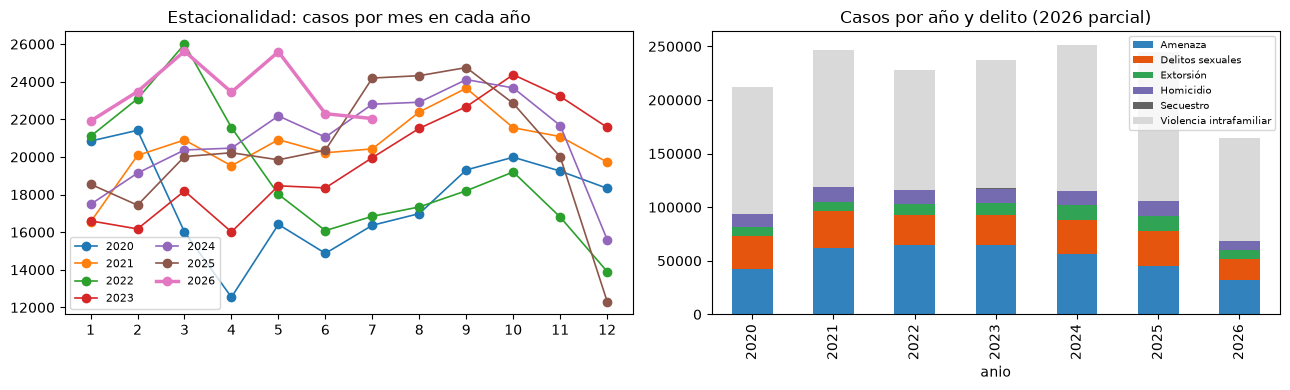

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for anio, g in data.groupby('anio'):
    s = g.groupby('mes').casos.sum()
    axes[0].plot(s.index, s.values, marker='o', label=anio, lw=2.5 if anio == CORTE_ANIO else 1.2)
axes[0].set_title('Estacionalidad: casos por mes en cada año'); axes[0].legend(ncol=2, fontsize=8); axes[0].set_xticks(range(1, 13))
data.pivot_table(index='anio', columns='delito', values='casos', aggfunc='sum').plot.bar(stacked=True, ax=axes[1], colormap='tab20c')
axes[1].set_title('Casos por año y delito (2026 parcial)'); axes[1].legend(fontsize=7)
plt.tight_layout();


## 3. Sobredispersión

Un modelo de Poisson supone que la varianza es igual a la media. Si dentro de cada serie la varianza es mucho mayor, hay sobredispersión y la binomial negativa es más adecuada (Var = μ + αμ²).


Series con varianza > media: 98%
Alpha estimado (Cameron-Trivedi): 0.0516
AIC Poisson: 192,503 | AIC binomial negativa: 109,784


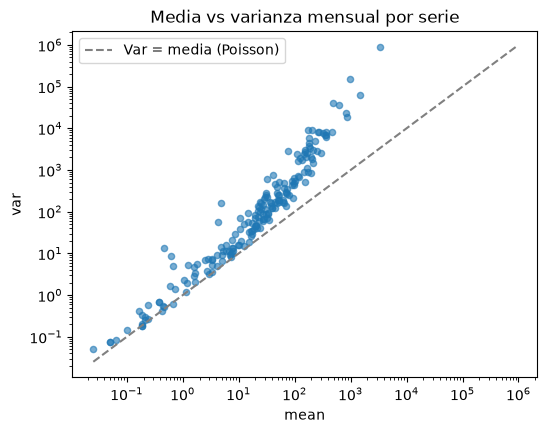

In [5]:
disp = panel.groupby('serie').casos.agg(['mean', 'var'])
disp = disp[disp['mean'] > 0]
print(f"Series con varianza > media: {(disp['var'] > disp['mean']).mean():.0%}")
print(f"Alpha estimado (Cameron-Trivedi): {resumen['alpha_binomial_negativa']:.4f}")
print(f"AIC Poisson: {resumen['aic_poisson']:,.0f} | AIC binomial negativa: {resumen['aic_binomial_negativa']:,.0f}")
ax = disp.plot.scatter(x='mean', y='var', logx=True, logy=True, alpha=.6, figsize=(6, 4.5), title='Media vs varianza mensual por serie')
lim = [disp['mean'].min(), disp['var'].max()]; ax.plot(lim, lim, '--', color='gray', label='Var = media (Poisson)'); ax.legend();


## 4. Estrategia de evaluación: backtest

El cierre de 2026 aún no se conoce, así que no puede usarse para medir el error. Se simula el mismo problema en años ya cerrados: con datos hasta julio de 2023 (2024, 2025) se pronostica agosto-diciembre y se compara el cierre pronosticado con el real. La métrica principal es el **WAPE** del cierre:

$$\text{WAPE} = \frac{\sum |\text{cierre pronosticado} - \text{cierre real}|}{\sum \text{cierre real}}$$

## 5. Iteraciones del modelo

1. **Línea base:** casos enero-julio escalados por el peso estacional histórico (últimos 3 años) de cada delito.
2. **MLG binomial negativa:** `casos ~ serie + mes + tendencia por delito + covid`, enlace log. Es la familia de conteos de los modelos lineales generalizados; los coeficientes se interpretan como razones de tasas (IRR = e^β).
3. **Gradient boosting con pérdida Poisson:** rezago de 12 meses, medias móviles de 3 y 12 meses, crecimiento anual, mes objetivo y horizonte. Hiperparámetros ajustados con validación cruzada temporal (`TimeSeriesSplit`) dentro del entrenamiento de cada backtest; la regularización se controla con profundidad, hoja mínima y penalización L2.


In [6]:
cols = ['version', 'regularizacion', 'wape', 'mae_cierre', 'rmse_cierre', 'error_nacional_pct', 'wape_2023', 'wape_2024', 'wape_2025']
resultados[cols].round(3)


,version,regularizacion,wape,mae_cierre,rmse_cierre,error_nacional_pct,wape_2023,wape_2024,wape_2025
0,3. Boosting Poisson,"Profundidad, hoja minima y L2",0.076,96.801,345.269,0.049,0.108,0.068,0.055
1,1. Linea base,No aplica,0.078,99.331,441.528,0.037,0.117,0.063,0.057
2,2. MLG binomial negativa,Dispersion alpha (Cameron-Trivedi),0.101,127.509,523.497,0.048,0.115,0.102,0.086


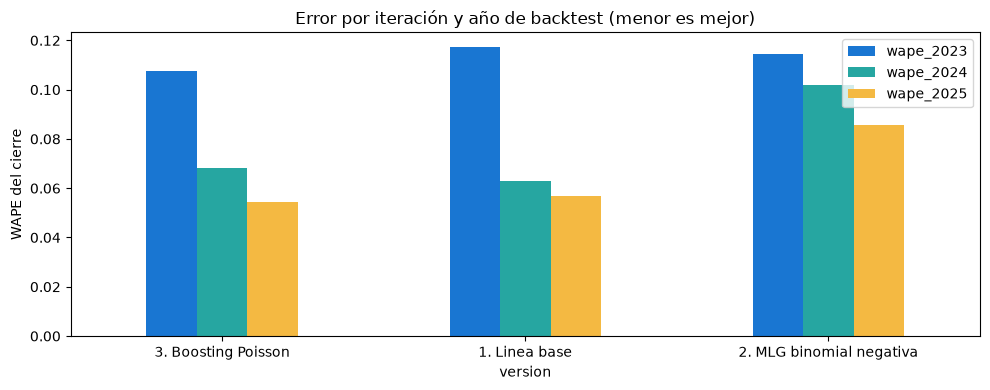

In [7]:
resultados.set_index('version')[['wape_2023', 'wape_2024', 'wape_2025']].plot.bar(figsize=(10, 4), color=['#1976D2', '#26A6A1', '#F4B942'])
plt.ylabel('WAPE del cierre'); plt.title('Error por iteración y año de backtest (menor es mejor)'); plt.xticks(rotation=0); plt.tight_layout();


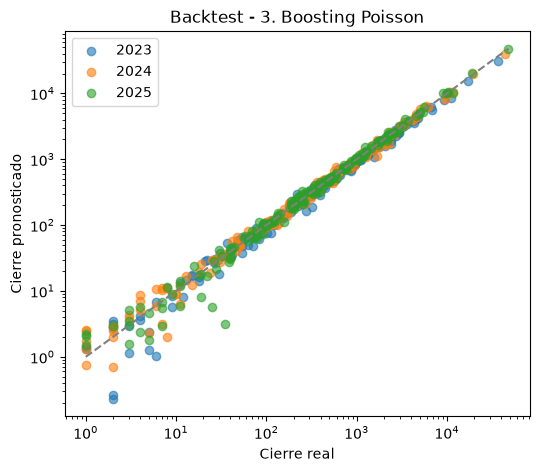

In [8]:
bt = backtest[backtest.version == resumen['modelo_seleccionado']]
fig, ax = plt.subplots(figsize=(6, 5))
for anio, g in bt.groupby('anio'):
    ax.scatter(g.cierre_real, g.cierre_pred, alpha=.6, label=anio)
lim = [1, bt[['cierre_real', 'cierre_pred']].max().max()]
ax.plot(lim, lim, '--', color='gray'); ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Cierre real'); ax.set_ylabel('Cierre pronosticado'); ax.set_title(f"Backtest - {resumen['modelo_seleccionado']}"); ax.legend();


**Lectura:** el boosting y la línea base quedan muy cerca; el MLG es el menos preciso porque impone una tendencia lineal (en escala log) para todo el periodo 2020-2026, y varias series cambiaron de dirección. 2023 es el año más difícil para todos: el segundo semestre de ese año creció más de lo que anticipaba la historia.


## 6. Interpretación del MLG (razones de tasas)


In [9]:
tabla_irr = coef[['termino', 'coeficiente', 'valor_p', 'irr', 'irr_inf', 'irr_sup']].copy()
tabla_irr['cambio_pct'] = (tabla_irr.irr - 1) * 100
tabla_irr.round(3)


,termino,coeficiente,valor_p,irr,irr_inf,irr_sup,cambio_pct
0,C(mes)[T.2],0.001,0.967,1.001,0.977,1.025,0.050
1,C(mes)[T.3],0.078,0.000,1.081,1.055,1.107,8.059
2,C(mes)[T.4],-0.029,0.019,0.971,0.948,0.995,-2.856
3,C(mes)[T.5],0.040,0.001,1.041,1.017,1.067,4.128
4,C(mes)[T.6],-0.002,0.877,0.998,0.974,1.022,-0.189
5,C(mes)[T.7],0.053,0.000,1.055,1.030,1.081,5.492
6,C(mes)[T.8],0.103,0.000,1.108,1.081,1.136,10.824
7,C(mes)[T.9],0.098,0.000,1.103,1.076,1.131,10.325
8,C(mes)[T.10],0.091,0.000,1.095,1.068,1.122,9.495
9,C(mes)[T.11],0.035,0.005,1.036,1.010,1.061,3.560


- **Tendencia anual:** la extorsión crece en promedio cerca de 11 % por año y el secuestro 26 %, manteniendo constantes la serie y el mes; las amenazas caen 2,4 % y los delitos sexuales 4,3 % por año. La violencia intrafamiliar no muestra tendencia significativa (p ≈ 0,09).
- **Estacionalidad:** frente a enero, agosto a octubre tienen alrededor de 10 % más casos; diciembre tiene 7 % menos (en parte por rezago de registro).
- **Covid:** en los meses de confinamiento estricto de 2020 los casos registrados fueron 23 % menores.

Al igual que el odds ratio en la regresión logística, la IRR describe un cambio multiplicativo, aquí sobre el número esperado de casos.


## 7. Importancia de variables del boosting


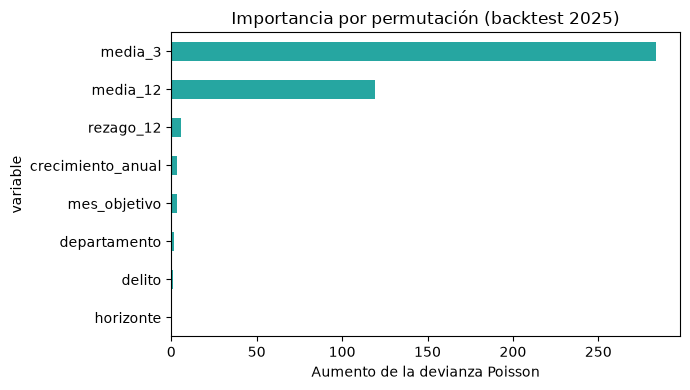

In [10]:
importancia.sort_values('importancia').plot.barh(x='variable', y='importancia', legend=False, figsize=(7, 4), color='#26A6A1')
plt.title('Importancia por permutación (backtest 2025)'); plt.xlabel('Aumento de la devianza Poisson'); plt.tight_layout();


## 8. Pronóstico de cierre 2026


Cierre 2025: 244,872
Cierre 2026 pronosticado: 272,688 (rango 267,947 - 300,895)


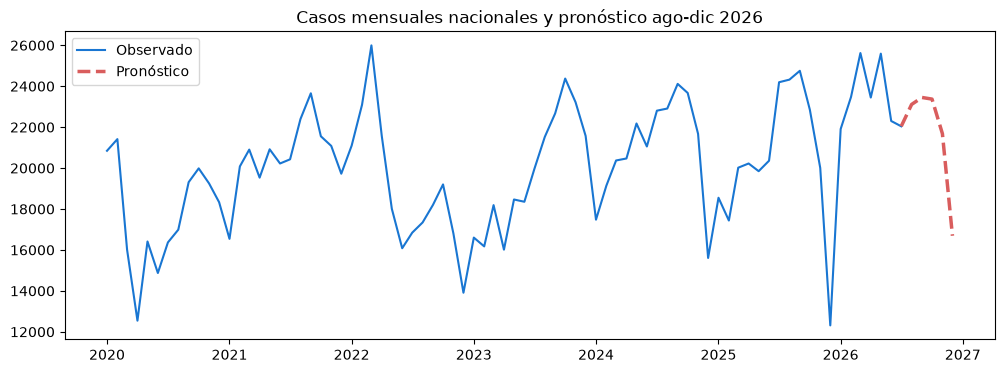

In [11]:
nac = panel.groupby('fecha').casos.sum()
fut = pronostico.groupby('mes').pred.sum()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(nac.index.to_timestamp(), nac.values, color='#1976D2', label='Observado')
fechas_fut = pd.to_datetime([f'{CORTE_ANIO}-{m:02d}-01' for m in fut.index])
ax.plot([nac.index[-1].to_timestamp(), *fechas_fut], [nac.values[-1], *fut.values], '--', color='#D95D5D', lw=2.5, label='Pronóstico')
ax.set_title('Casos mensuales nacionales y pronóstico ago-dic 2026'); ax.legend();
print(f"Cierre {CORTE_ANIO - 1}: {resumen['cierre_nacional_anterior']:,}")
print(f"Cierre {CORTE_ANIO} pronosticado: {resumen['cierre_nacional_pronosticado']:,.0f} "
      f"(rango {resumen['cierre_nacional_inf']:,.0f} - {resumen['cierre_nacional_sup']:,.0f})")


In [12]:
por_delito = cierre.groupby('delito')[['cierre_anterior', 'observado_ytd', 'cierre_pred']].sum()
por_delito['variacion_pct'] = (por_delito.cierre_pred / por_delito.cierre_anterior - 1) * 100
por_delito.round(1).sort_values('cierre_pred', ascending=False)


,cierre_anterior,observado_ytd,cierre_pred,variacion_pct
delito,,,,
Violencia intrafamiliar,138804,96108,157430.3,13.4
Amenaza,44904,32046,52587.9,17.1
Delitos sexuales,32984,19467,33016.6,0.1
Extorsión,13441,8272,14691.7,9.3
Homicidio,14037,8271,14470.3,3.1
Secuestro,702,221,491.6,-30.0


In [13]:
print(cierre.tendencia.value_counts())
cierre.sort_values('variacion_pct', ascending=False)[['departamento', 'delito', 'cierre_anterior', 'cierre_pred', 'variacion_pct']].query('cierre_anterior >= 500').head(10).round(2)


tendencia
AUMENTO        96
DISMINUCIÓN    55
SIN CAMBIO     42
Name: count, dtype: int64


,departamento,delito,cierre_anterior,cierre_pred,variacion_pct
17,ATLÁNTICO,Amenaza,1835,3897.18,1.12
20,ATLÁNTICO,Homicidio,856,1381.73,0.61
135,NORTE DE SANTANDER,Violencia intrafamiliar,2194,3453.14,0.57
46,CALDAS,Violencia intrafamiliar,1192,1733.54,0.45
5,ANTIOQUIA,Amenaza,3395,4761.67,0.40
112,MAGDALENA,Amenaza,1249,1662.84,0.33
171,TOLIMA,Amenaza,1446,1912.21,0.32
23,BOGOTA,Amenaza,11759,15097.99,0.28
118,META,Amenaza,1036,1329.94,0.28
123,META,Violencia intrafamiliar,2854,3607.61,0.26


## 9. Conclusiones

- Con el corte de julio es posible pronosticar el cierre anual por departamento y delito con un error cercano al 8 % (WAPE), y alrededor de 5 % en el total nacional.
- El boosting con pérdida Poisson fue el más preciso, pero la línea base estacional queda muy cerca: la señal principal está en el nivel reciente de cada serie.
- El MLG binomial negativa es menos preciso, pero es el que explica el comportamiento (tendencias por delito, estacionalidad, efecto covid) y confirma la sobredispersión de los conteos.
- Se espera que 2026 cierre con unos 272.700 casos, alrededor de 11 % más que 2025, con aumentos en violencia intrafamiliar, amenazas y extorsión.
- Los datos son casos registrados: el rezago de registro (especialmente en diciembre) y la denuncia afectan tanto el pronóstico como los cierres usados para evaluarlo.

El dashboard `app.py` permite filtrar por departamento y delito, revisar el pronóstico mensual, el mapa de variaciones y el desempeño de cada iteración.
